# UK Online Retail: Sales Analysis, Customer Segmentation and SAP-Aligned Data Model

**Author:** Shirin Aghaei
**Tools:** Python (pandas, matplotlib), Google Colab

## Overview
This project analyses two years of real transaction data from a UK-based online giftware retailer. It covers data cleaning, sales analysis, cancellation analysis, RFM customer segmentation and the mapping of the cleaned data to an SAP SD (Sales and Distribution) billing structure.

All monetary values are in pounds sterling (£). This is a personal portfolio project using a public dataset.

In [1]:
import os

path = "/content/drive/MyDrive/uk_retail_project/online_retail_II.xlsx"
print("Drive connected:", os.path.exists("/content/drive/MyDrive"))
print("Folder found:", os.path.exists("/content/drive/MyDrive/uk_retail_project"))
print("File found:", os.path.exists(path))

Drive connected: True
Folder found: True
File found: True


In [2]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from IPython.display import display

PROJECT_DIR = "/content/drive/MyDrive/uk_retail_project/"
DATA_PATH = PROJECT_DIR + "online_retail_II.xlsx"
IMG_DIR = PROJECT_DIR + "images/"
OUTPUT_DIR = PROJECT_DIR + "output/"
os.makedirs(IMG_DIR, exist_ok=True)
os.makedirs(OUTPUT_DIR, exist_ok=True)

gbp_axis = FuncFormatter(lambda x, pos: f"£{x:,.0f}")
print("Data file found:", os.path.exists(DATA_PATH))

Data file found: True


## 1. Business Questions
1. How does monthly revenue change over time, and is there seasonality?
2. Which products and countries generate the most revenue?
3. How much revenue is lost to cancelled orders?
4. How can customers be segmented by purchasing behaviour (RFM), and how concentrated is revenue among the best customers?
5. How would this data look in an SAP SD billing structure?

In [3]:
sheets = pd.read_excel(DATA_PATH, sheet_name=None)
raw = pd.concat(sheets.values(), ignore_index=True)
raw = raw.rename(columns={"Customer ID": "CustomerID"})
raw.to_pickle(PROJECT_DIR + "raw_data.pkl")

print(f"Rows: {raw.shape[0]:,} | Columns: {raw.shape[1]}")
raw.head()

Rows: 1,067,371 | Columns: 8


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,CustomerID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


## 2. Data Audit
Before cleaning, the raw data is checked for missing values, duplicates, negative quantities, non-positive prices and the date range covered.

In [4]:
audit = pd.DataFrame({
    "Missing values": raw.isna().sum(),
    "Missing (%)": raw.isna().mean() * 100,
})
display(audit)

print(f"Duplicate rows: {raw.duplicated().sum():,}")
print(f"Negative quantities: {(raw['Quantity'] < 0).sum():,}")
print(f"Zero or negative prices: {(raw['Price'] <= 0).sum():,}")
print(f"Date range: {raw['InvoiceDate'].min():%d %b %Y} to {raw['InvoiceDate'].max():%d %b %Y}")

,Missing values,Missing (%)
Invoice,0,0.000000
StockCode,0,0.000000
Description,4382,0.410541
Quantity,0,0.000000
InvoiceDate,0,0.000000
Price,0,0.000000
CustomerID,243007,22.766873
Country,0,0.000000


Duplicate rows: 34,335
Negative quantities: 22,950
Zero or negative prices: 6,207
Date range: 01 Dec 2009 to 09 Dec 2011


## 3. Data Cleaning
The following rules were applied, in order:
1. Exact duplicate rows were removed.
2. Non-product stock codes (postage, manual adjustments, bank charges, fees, test codes and gift vouchers) were removed because they do not represent merchandise sales.
3. Cancelled invoices (invoice numbers starting with "C") were separated for a dedicated cancellation analysis.
4. Rows with non-positive quantities or prices were removed.
5. Rows without a Customer ID were kept for sales analysis but excluded from customer segmentation.

A revenue column was calculated as quantity multiplied by unit price (£).

In [5]:
df = raw.copy()
log = [("Raw rows", len(df))]

df = df.drop_duplicates()
log.append(("Exact duplicate rows removed", len(df)))

df["Invoice"] = df["Invoice"].astype(str)
df["CustomerID"] = df["CustomerID"].astype("Int64")
df["StockCode"] = df["StockCode"].astype(str).str.upper().str.strip()
df["Description"] = df["Description"].astype("string").str.strip().str.upper()

non_product_codes = [
    "POST", "D", "M", "BANK CHARGES", "DOT", "CRUK", "AMAZONFEE", "B", "S",
    "ADJUST", "ADJUST2", "TEST001", "TEST002", "PADS",
]
is_non_product = df["StockCode"].isin(non_product_codes) | df["StockCode"].str.startswith("GIFT")
df = df[~is_non_product]
log.append(("Non-product codes removed", len(df)))

is_cancellation = df["Invoice"].str.startswith("C")
cancellations = df[is_cancellation].copy()
df = df[~is_cancellation]
log.append(("Cancelled invoices separated", len(df)))

df = df[(df["Quantity"] > 0) & (df["Price"] > 0)].copy()
log.append(("Invalid quantities or prices removed", len(df)))

# ---- NEW: remove extreme orders fully reversed by a cancellation ----
big = df[df["Quantity"] >= 10000].dropna(subset=["CustomerID"])
can = cancellations.dropna(subset=["CustomerID"]).copy()
can["Quantity_pos"] = -can["Quantity"]
pairs = big.reset_index().merge(
    can.reset_index(), left_on=["CustomerID", "StockCode", "Quantity"],
    right_on=["CustomerID", "StockCode", "Quantity_pos"], suffixes=("_sale", "_canc"))
pairs = pairs[pairs["InvoiceDate_canc"] >= pairs["InvoiceDate_sale"]]
display(pairs[["Invoice_sale", "InvoiceDate_sale", "StockCode", "Quantity_sale",
               "Price_sale", "Invoice_canc", "InvoiceDate_canc"]])
print("Reversed sales value removed (£):", (pairs["Quantity_sale"] * pairs["Price_sale"]).sum())
df = df.drop(index=pairs["index_sale"].unique())
cancellations = cancellations.drop(index=pairs["index_canc"].unique())
log.append(("Extreme reversed orders removed", len(df)))

df["Revenue"] = df["Quantity"] * df["Price"]
df["InvoiceMonth"] = df["InvoiceDate"].dt.to_period("M").dt.to_timestamp()

cleaning_log = pd.DataFrame(log, columns=["Step", "Rows remaining"])
cleaning_log["Rows removed"] = (
    cleaning_log["Rows remaining"].shift(1) - cleaning_log["Rows remaining"]
).fillna(0).astype(int)
display(cleaning_log)

,Invoice_sale,InvoiceDate_sale,StockCode,Quantity_sale,Price_sale,Invoice_canc,InvoiceDate_canc
0,541431,2011-01-18 10:01:00,23166,74215,1.04,C541433,2011-01-18 10:17:00
1,581483,2011-12-09 09:15:00,23843,80995,2.08,C581484,2011-12-09 09:27:00


Reversed sales value removed (£): 245653.2


,Step,Rows remaining,Rows removed
0,Raw rows,1067371,0
1,Exact duplicate rows removed,1033036,34335
2,Non-product codes removed,1027494,5542
3,Cancelled invoices separated,1009573,17921
4,Invalid quantities or prices removed,1003607,5966
5,Extreme reversed orders removed,1003605,2


## 4. Monthly Revenue Trend
The final month in the dataset is incomplete (the data ends part-way through December 2011), so it is excluded from trend and growth calculations to avoid a misleading drop.

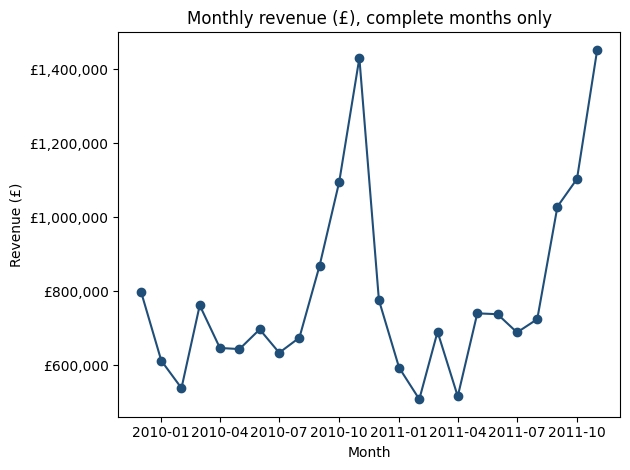

Gross sales revenue (before cancellations): £19,411,634
Peak month: November 2011 (£1,453,266)
Lowest complete month: February 2011 (£508,015)
Year-on-year change (Dec 2010 to Nov 2011 vs Dec 2009 to Nov 2010): +1.7%


In [6]:
monthly = df.groupby("InvoiceMonth")["Revenue"].sum()
last_date = df["InvoiceDate"].max()
monthly_complete = monthly.iloc[:-1] if last_date.day < last_date.days_in_month else monthly

fig, ax = plt.subplots()
ax.plot(monthly_complete.index, monthly_complete.values, marker="o", color="#1f4e79")
ax.yaxis.set_major_formatter(gbp_axis)
ax.set_title("Monthly revenue (£), complete months only")
ax.set_xlabel("Month")
ax.set_ylabel("Revenue (£)")
plt.tight_layout()
plt.savefig(IMG_DIR + "01_monthly_revenue.png", dpi=150, bbox_inches="tight")
plt.show()

total_revenue = df["Revenue"].sum()
peak_month, peak_value = monthly_complete.idxmax(), monthly_complete.max()
low_month, low_value = monthly_complete.idxmin(), monthly_complete.min()

yoy = None
if len(monthly_complete) == 24:
    yoy = monthly_complete.iloc[12:].sum() / monthly_complete.iloc[:12].sum() - 1

print(f"Gross sales revenue (before cancellations): £{total_revenue:,.0f}")
print(f"Peak month: {peak_month:%B %Y} (£{peak_value:,.0f})")
print(f"Lowest complete month: {low_month:%B %Y} (£{low_value:,.0f})")
if yoy is not None:
    print(f"Year-on-year change (Dec 2010 to Nov 2011 vs Dec 2009 to Nov 2010): {yoy:+.1%}")

## 5. Top Products and Countries

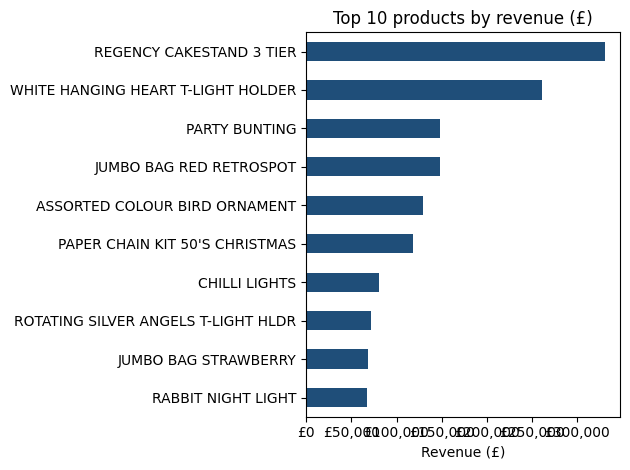

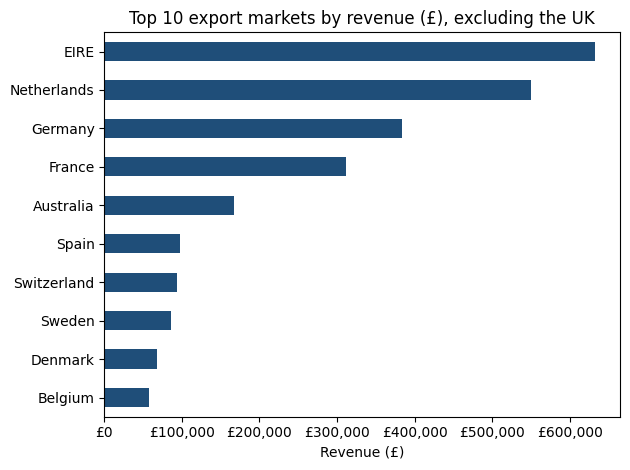

Top 10 products generate 7.3% of revenue.
The UK generates 85.3% of revenue.
Largest export market: EIRE (£633,269).


In [7]:
top_products = df.groupby("Description")["Revenue"].sum().sort_values(ascending=False).head(10)
top_products_share = top_products.sum() / total_revenue

fig, ax = plt.subplots()
top_products.sort_values().plot(kind="barh", ax=ax, color="#1f4e79")
ax.xaxis.set_major_formatter(gbp_axis)
ax.set_title("Top 10 products by revenue (£)")
ax.set_xlabel("Revenue (£)")
ax.set_ylabel("")
plt.tight_layout()
plt.savefig(IMG_DIR + "02_top_products.png", dpi=150, bbox_inches="tight")
plt.show()

country_revenue = df.groupby("Country")["Revenue"].sum().sort_values(ascending=False)
uk_share = country_revenue.get("United Kingdom", 0) / total_revenue
export_countries = country_revenue.drop(labels=["United Kingdom"], errors="ignore")
top_export_countries = export_countries.head(10)

fig, ax = plt.subplots()
top_export_countries.sort_values().plot(kind="barh", ax=ax, color="#1f4e79")
ax.xaxis.set_major_formatter(gbp_axis)
ax.set_title("Top 10 export markets by revenue (£), excluding the UK")
ax.set_xlabel("Revenue (£)")
ax.set_ylabel("")
plt.tight_layout()
plt.savefig(IMG_DIR + "03_top_export_markets.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"Top 10 products generate {top_products_share:.1%} of revenue.")
print(f"The UK generates {uk_share:.1%} of revenue.")
print(f"Largest export market: {export_countries.index[0]} (£{export_countries.iloc[0]:,.0f}).")

## 6. Cancellation Analysis
Cancelled invoices are measured by count and by value (£) relative to completed sales.

In [8]:
cancelled_invoices = cancellations["Invoice"].nunique()
sold_invoices = df["Invoice"].nunique()
cancellation_rate = cancelled_invoices / (cancelled_invoices + sold_invoices)
cancelled_value = (cancellations["Quantity"].abs() * cancellations["Price"]).sum()
cancelled_value_share = cancelled_value / total_revenue

print(f"Completed invoices: {sold_invoices:,}")
print(f"Cancelled invoices: {cancelled_invoices:,} ({cancellation_rate:.1%} of all invoices)")
print(f"Value of cancelled orders: £{cancelled_value:,.0f} ({cancelled_value_share:.1%} of sales revenue)")

Completed invoices: 39,521
Cancelled invoices: 7,407 (15.8% of all invoices)
Value of cancelled orders: £471,063 (2.4% of sales revenue)


In [9]:
cancellations["CancelValue"] = cancellations["Quantity"].abs() * cancellations["Price"]
gross = df["Revenue"].sum()
cancelled = cancellations["CancelValue"].sum()
net = gross - cancelled
print(f"Gross £{gross:,.0f} | Cancelled £{cancelled:,.0f} | Net £{net:,.0f}")
print(f"Cancelled value / Gross: {cancelled/gross:.1%}")

Gross £19,411,634 | Cancelled £471,063 | Net £18,940,572
Cancelled value / Gross: 2.4%


In [10]:
s = df.dropna(subset=["CustomerID"]).copy()
c = cancellations.dropna(subset=["CustomerID"]).copy()
s["CustomerID"] = s["CustomerID"].astype(int)
c["CustomerID"] = c["CustomerID"].astype(int)
s = s[["CustomerID", "StockCode", "InvoiceDate", "Invoice"]].rename(
    columns={"InvoiceDate": "orig_date", "Invoice": "orig_invoice"})
s["InvoiceDate"] = s["orig_date"]
linked = pd.merge_asof(c.sort_values("InvoiceDate"), s.sort_values("InvoiceDate"),
    on="InvoiceDate", by=["CustomerID", "StockCode"], direction="backward")
linked["matched"] = linked["orig_invoice"].notna()
linked["days_to_cancel"] = (linked["InvoiceDate"] - linked["orig_date"]).dt.days
no_id = cancellations.loc[cancellations["CustomerID"].isna(), "CancelValue"].sum()
print(f"Matched cancellation lines: {linked['matched'].mean():.1%}")
print(f"Cancelled £ with no Customer ID (cannot be matched): {no_id:,.0f}")
print(linked["days_to_cancel"].describe())

Matched cancellation lines: 91.3%
Cancelled £ with no Customer ID (cannot be matched): 6,488
count    16060.000000
mean        31.602864
std         59.694309
min          0.000000
25%          4.000000
50%         10.000000
75%         30.000000
max        655.000000
Name: days_to_cancel, dtype: float64


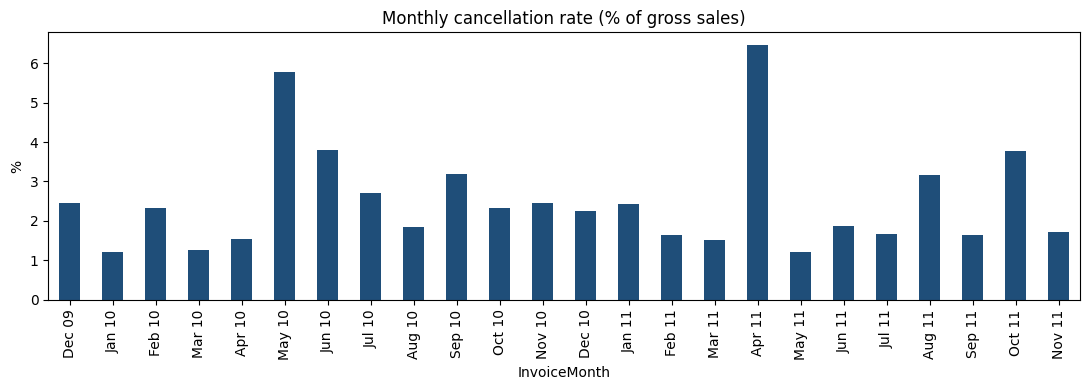

Top 10 products by cancelled value (£):


,gross,cancelled,rate,Description
StockCode,,,,
22423,330590.32,16545.30,5.0,REGENCY CAKESTAND 3 TIER
85123A,261168.73,9387.10,3.6,WHITE HANGING HEART T-LIGHT HOLDER
71477,44680.75,7164.12,16.0,COLOUR GLASS. STAR T-LIGHT HOLDER
21108,25407.27,6614.37,26.0,FAIRY CAKE FLANNEL ASSORTED COLOUR
79323W,18048.72,6421.10,35.6,WHITE CHERRY LIGHTS
21843,64918.30,5270.25,8.1,RED RETROSPOT CAKE STAND
84078A,43844.96,5187.65,11.8,SET/4 WHITE RETRO STORAGE CUBES
23113,5868.50,4803.06,81.8,PANTRY CHOPPING BOARD
48185,45723.84,4678.68,10.2,DOORMAT FAIRY CAKE


Highest cancellation rate (products with gross > £5,000):


,gross,cancelled,rate,Description
StockCode,,,,
23113,5868.50,4803.06,81.8,PANTRY CHOPPING BOARD
85220,6875.00,3645.65,53.0,SMALL FAIRY CAKE FRIDGE MAGNETS
79323W,18048.72,6421.10,35.6,WHITE CHERRY LIGHTS
22341,5698.89,1858.20,32.6,LOVE GARLAND PAINTED ZINC
79323LP,8481.19,2702.80,31.9,LIGHT PINK CHERRY LIGHTS
79323P,13787.93,4021.35,29.2,PINK CHERRY LIGHTS
21108,25407.27,6614.37,26.0,FAIRY CAKE FLANNEL ASSORTED COLOUR
22656,9290.00,2368.50,25.5,VINTAGE BLUE KITCHEN CABINET
22670,5510.57,1340.56,24.3,FRENCH WC SIGN BLUE METAL


In [11]:
cancellations["InvoiceMonth"] = cancellations["InvoiceDate"].dt.to_period("M").dt.to_timestamp()
rate = (cancellations.groupby("InvoiceMonth")["CancelValue"].sum() / monthly).reindex(monthly_complete.index) * 100
rate.index = rate.index.strftime("%b %y")
ax = rate.plot(kind="bar", figsize=(11, 4), color="#1f4e79")
ax.set_title("Monthly cancellation rate (% of gross sales)"); ax.set_ylabel("%")
plt.tight_layout(); plt.savefig(IMG_DIR + "05_cancellation_rate.png", dpi=150, bbox_inches="tight"); plt.show()

desc = df.groupby("StockCode")["Description"].agg(lambda x: x.mode().iloc[0] if not x.mode().empty else "")
p = pd.DataFrame({"gross": df.groupby("StockCode")["Revenue"].sum(),
                  "cancelled": cancellations.groupby("StockCode")["CancelValue"].sum()}).fillna(0)
p["rate"] = (p["cancelled"] / p["gross"] * 100).round(1)
p = p.join(desc)
print("Top 10 products by cancelled value (£):")
display(p.sort_values("cancelled", ascending=False).head(10))
print("Highest cancellation rate (products with gross > £5,000):")
display(p[p["gross"] > 5000].sort_values("rate", ascending=False).head(10))

In [12]:
cust = cancellations.dropna(subset=["CustomerID"]).groupby("CustomerID")["CancelValue"].sum().sort_values(ascending=False)
cum = cust.cumsum() / cust.sum()
n80 = int((cum <= 0.8).sum() + 1)
print(f"{n80} of {len(cust)} customers ({n80/len(cust):.1%}) make 80% of cancelled value")

376 of 2443 customers (15.4%) make 80% of cancelled value


In [13]:
rate_all = (cancellations.groupby("InvoiceMonth")["CancelValue"].sum() / monthly).reindex(monthly_complete.index) * 100
excl = cancellations[cancellations["Invoice"] != "C550456"]
rate_ex = (excl.groupby("InvoiceMonth")["CancelValue"].sum() / monthly).reindex(monthly_complete.index) * 100
apr = pd.Timestamp("2011-04-01")
print(f"Apr 2011 rate: with C550456 {rate_all[apr]:.2f}% | without {rate_ex[apr]:.2f}%")
print(f"Overall cancelled/gross: with {cancelled/gross:.2%} | without {excl['CancelValue'].sum()/gross:.2%}")

Apr 2011 rate: with C550456 6.46% | without 2.00%
Overall cancelled/gross: with 2.43% | without 2.31%


In [14]:
cnt = cancellations.groupby("StockCode")["CustomerID"].nunique().rename("customers")
by_pc = cancellations.dropna(subset=["CustomerID"]).groupby(["StockCode", "CustomerID"])["CancelValue"].sum()
top_share = (by_pc.groupby("StockCode").max() / by_pc.groupby("StockCode").sum() * 100).round(0).rename("top_cust_%")
rob = p.join(cnt).join(top_share)
rob = rob[(rob["gross"] > 5000) & (rob["customers"] >= 10)].sort_values("rate", ascending=False)
display(rob.head(10))

,gross,cancelled,rate,Description,customers,top_cust_%
StockCode,,,,,,
79323W,18048.72,6421.10,35.6,WHITE CHERRY LIGHTS,109.0,4.0
79323LP,8481.19,2702.80,31.9,LIGHT PINK CHERRY LIGHTS,55.0,7.0
79323P,13787.93,4021.35,29.2,PINK CHERRY LIGHTS,78.0,12.0
22656,9290.00,2368.50,25.5,VINTAGE BLUE KITCHEN CABINET,12.0,13.0
21735,11112.85,2535.60,22.8,TWO DOOR CURIO CABINET,32.0,64.0
85063,5426.74,1060.70,19.5,CREAM SWEETHEART MAGAZINE RACK,30.0,10.0
22655,12845.00,2320.50,18.1,VINTAGE RED KITCHEN CABINET,10.0,13.0
22618,6984.35,1226.07,17.6,COOKING SET RETROSPOT,33.0,20.0
22191,16216.05,2703.85,16.7,IVORY DINER WALL CLOCK,20.0,90.0


## 7. Customer Segmentation (RFM)
RFM scores each customer on three measures:
- **Recency:** days since the last purchase (lower is better)
- **Frequency:** number of distinct invoices
- **Monetary:** total spend (£)

Each measure is scored from 1 to 5 using quintiles, and the three scores are added together (range 3 to 15). Segments: Champions (13 to 15), Loyal (10 to 12), Potential (7 to 9), At Risk (5 to 6) and Lost (3 to 4). Only transactions with a Customer ID can be included.

,Customers,Revenue_GBP,Avg_spend_GBP,Avg_recency_days,Customer share (%),Revenue share (%)
Segment,,,,,,
Champions,1285,12290666.25,9564.720817,25.571984,21.954553,73.004568
Loyal,1355,2827817.86,2086.950450,96.425830,23.150521,16.796780
Potential,1446,1189131.60,822.359336,200.178423,24.705279,7.063249
At Risk,965,369546.28,382.949513,318.511917,16.487271,2.195045
Lost,802,158313.53,197.398416,513.874065,13.702375,0.940357


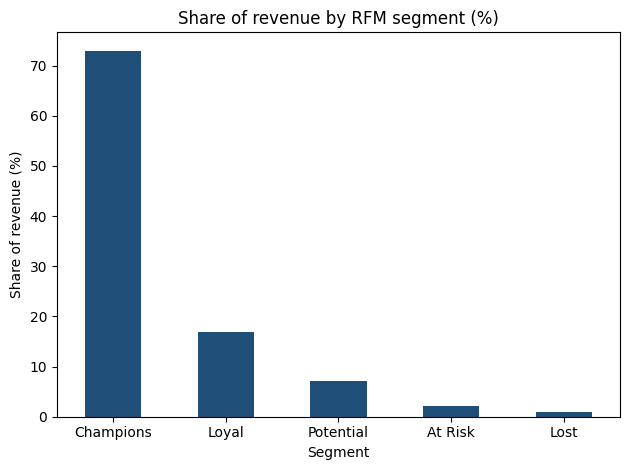

Identified customers: 5,853
Revenue from transactions without a Customer ID: 13.3%
The top 20% of identified customers generate 76.9% of identified revenue.


In [15]:
unattributed_share = df.loc[df["CustomerID"].isna(), "Revenue"].sum() / total_revenue

rfm_data = df.dropna(subset=["CustomerID"]).copy()
rfm_data["CustomerID"] = rfm_data["CustomerID"].astype(int)
snapshot_date = rfm_data["InvoiceDate"].max() + pd.Timedelta(days=1)

rfm = rfm_data.groupby("CustomerID").agg(
    Recency=("InvoiceDate", lambda x: (snapshot_date - x.max()).days),
    Frequency=("Invoice", "nunique"),
    Monetary=("Revenue", "sum"),
)

rfm["R"] = pd.qcut(rfm["Recency"].rank(method="first"), 5, labels=[5, 4, 3, 2, 1]).astype(int)
rfm["F"] = pd.qcut(rfm["Frequency"].rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)
rfm["M"] = pd.qcut(rfm["Monetary"].rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)
rfm["Score"] = rfm["R"] + rfm["F"] + rfm["M"]

def assign_segment(score):
    if score >= 13:
        return "Champions"
    if score >= 10:
        return "Loyal"
    if score >= 7:
        return "Potential"
    if score >= 5:
        return "At Risk"
    return "Lost"

rfm["Segment"] = rfm["Score"].apply(assign_segment)

segment_order = ["Champions", "Loyal", "Potential", "At Risk", "Lost"]
segment_summary = rfm.groupby("Segment").agg(
    Customers=("Monetary", "count"),
    Revenue_GBP=("Monetary", "sum"),
    Avg_spend_GBP=("Monetary", "mean"),
    Avg_recency_days=("Recency", "mean"),
).reindex(segment_order)
segment_summary["Customer share (%)"] = segment_summary["Customers"] / segment_summary["Customers"].sum() * 100
segment_summary["Revenue share (%)"] = segment_summary["Revenue_GBP"] / segment_summary["Revenue_GBP"].sum() * 100
display(segment_summary)

fig, ax = plt.subplots()
segment_summary["Revenue share (%)"].plot(kind="bar", ax=ax, color="#1f4e79")
ax.set_title("Share of revenue by RFM segment (%)")
ax.set_xlabel("Segment")
ax.set_ylabel("Share of revenue (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(IMG_DIR + "04_rfm_segments.png", dpi=150, bbox_inches="tight")
plt.show()

cust_rev = rfm["Monetary"].sort_values(ascending=False)
top20_share = cust_rev.head(int(len(cust_rev) * 0.2)).sum() / cust_rev.sum()

champions_customer_share = segment_summary.loc["Champions", "Customer share (%)"]
champions_revenue_share = segment_summary.loc["Champions", "Revenue share (%)"]
at_risk_customers = int(segment_summary.loc["At Risk", "Customers"])
at_risk_revenue = segment_summary.loc["At Risk", "Revenue_GBP"]

print(f"Identified customers: {len(rfm):,}")
print(f"Revenue from transactions without a Customer ID: {unattributed_share:.1%}")
print(f"The top 20% of identified customers generate {top20_share:.1%} of identified revenue.")

In [16]:
cc = cancellations.dropna(subset=["CustomerID"]).copy()
cc["CustomerID"] = cc["CustomerID"].astype(int)
cancel_by_cust = cc.groupby("CustomerID")["CancelValue"].sum().rename("Cancelled")
seg = rfm.join(cancel_by_cust, how="left").fillna({"Cancelled": 0})
seg_sum = seg.groupby("Segment").agg(Revenue=("Monetary", "sum"), Cancelled=("Cancelled", "sum"))
seg_sum["Cancel rate %"] = seg_sum["Cancelled"] / seg_sum["Revenue"] * 100
display(seg_sum.reindex(segment_order).round(1))

,Revenue,Cancelled,Cancel rate %
Segment,,,
Champions,12290666.2,304751.5,2.5
Loyal,2827817.9,108101.0,3.8
Potential,1189131.6,36386.9,3.1
At Risk,369546.3,10497.8,2.8
Lost,158313.5,3432.0,2.2


## 8. SAP-Aligned Data Model
To show how this retail data would look in an SAP environment, the cleaned transactions were restructured into tables that follow SAP SD (Sales and Distribution) billing naming conventions. **This is a structural mapping of a public dataset. No live SAP system was used.**

| Dataset field | SAP table | SAP field | Meaning |
|---|---|---|---|
| Invoice | VBRK / VBRP | VBELN | Billing document number |
| InvoiceDate | VBRK | FKDAT | Billing date |
| CustomerID | VBRK / KNA1 | KUNAG / KUNNR | Sold-to party / customer number |
| Country | KNA1 | LAND1 | Customer country (country name used here, not an ISO key) |
| StockCode | VBRP / MAKT | MATNR | Material number |
| Description | VBRP / MAKT | ARKTX / MAKTX | Item short text / material description |
| Quantity | VBRP | FKIMG | Billed quantity |
| Price | VBRP | NETPR | Net price per unit |
| Revenue | VBRP / VBRK | NETWR | Net value (item level and document level) |
| Constant "GBP" | VBRP / VBRK | WAERK | Document currency |

Tables created: **VBRK** (billing header), **VBRP** (billing items), **KNA1** (customer master) and **MAKT** (material descriptions). Six integrity checks confirm that headers, items and master data reconcile.

In [17]:
sap = df.copy()
sap["WAERK"] = "GBP"
sap = sap.sort_values(["Invoice", "InvoiceDate"])
sap["POSNR"] = (sap.groupby("Invoice").cumcount() + 1) * 10

vbrp = sap.rename(columns={
    "Invoice": "VBELN", "StockCode": "MATNR", "Description": "ARKTX",
    "Quantity": "FKIMG", "Price": "NETPR", "Revenue": "NETWR",
})[["VBELN", "POSNR", "MATNR", "ARKTX", "FKIMG", "NETPR", "NETWR", "WAERK"]]

vbrk = (
    sap.groupby("Invoice")
    .agg(FKDAT=("InvoiceDate", "min"), KUNAG=("CustomerID", "first"),
         NETWR=("Revenue", "sum"), WAERK=("WAERK", "first"))
    .reset_index()
    .rename(columns={"Invoice": "VBELN"})
)

kna1 = (
    sap.dropna(subset=["CustomerID"])
    .groupby("CustomerID")
    .agg(LAND1=("Country", "first"))
    .reset_index()
    .rename(columns={"CustomerID": "KUNNR"})
)

makt = (
    sap.groupby("StockCode")
    .agg(MAKTX=("Description", lambda x: x.mode().iloc[0] if not x.mode().empty else ""))
    .reset_index()
    .rename(columns={"StockCode": "MATNR"})
)

chk = vbrp.groupby("VBELN")["NETWR"].sum().rename("items").to_frame().join(
    vbrk.set_index("VBELN")["NETWR"])
print("Header = sum of its items:", np.isclose(chk["items"], chk["NETWR"]).all())
print("Total = cleaned revenue:", np.isclose(vbrp["NETWR"].sum(), df["Revenue"].sum()))
print("VBELN+POSNR unique:", not vbrp.duplicated(["VBELN", "POSNR"]).any())
print("All items have a header:", vbrp["VBELN"].isin(vbrk["VBELN"]).all())
print("All materials in MAKT:", vbrp["MATNR"].isin(makt["MATNR"]).all())
print("All customers in KNA1:", vbrk["KUNAG"].dropna().isin(kna1["KUNNR"]).all())

vbrk.to_csv(OUTPUT_DIR + "sap_vbrk.csv", index=False)
vbrp.to_csv(OUTPUT_DIR + "sap_vbrp.csv", index=False)
kna1.to_csv(OUTPUT_DIR + "sap_kna1.csv", index=False)
makt.to_csv(OUTPUT_DIR + "sap_makt.csv", index=False)
rfm.reset_index().to_csv(OUTPUT_DIR + "rfm_customers.csv", index=False)

display(vbrk.head(3))
display(vbrp.head(3))

Header = sum of its items: True
Total = cleaned revenue: True
VBELN+POSNR unique: True
All items have a header: True
All materials in MAKT: True
All customers in KNA1: True


,VBELN,FKDAT,KUNAG,NETWR,WAERK
0,489434,2009-12-01 07:45:00,13085,505.30,GBP
1,489435,2009-12-01 07:46:00,13085,145.80,GBP
2,489436,2009-12-01 09:06:00,13078,630.33,GBP


,VBELN,POSNR,MATNR,ARKTX,FKIMG,NETPR,NETWR,WAERK
0,489434,10,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,6.95,83.4,GBP
1,489434,20,79323P,PINK CHERRY LIGHTS,12,6.75,81.0,GBP
2,489434,30,79323W,WHITE CHERRY LIGHTS,12,6.75,81.0,GBP


In [18]:
lines = [
    f"- Data: {len(raw):,} raw transaction lines; {len(df):,} valid sales lines after cleaning "
    f"({raw['InvoiceDate'].min():%d %b %Y} to {raw['InvoiceDate'].max():%d %b %Y}).",
    f"- Gross sales revenue (before cancellations) was £{total_revenue:,.0f} across {sold_invoices:,} invoices.",
    f"- Revenue peaked in {peak_month:%B %Y} (£{peak_value:,.0f}); the lowest complete month was "
    f"{low_month:%B %Y} (£{low_value:,.0f}).",
]
if yoy is not None:
    lines.append(f"- Revenue for December 2010 to November 2011 was {yoy:+.1%} compared with "
                 f"December 2009 to November 2010 (complete months only).")
lines += [
    f"- The top 10 products generated {top_products_share:.1%} of revenue.",
    f"- The UK accounted for {uk_share:.1%} of revenue; the largest export market was "
    f"{export_countries.index[0]} (£{export_countries.iloc[0]:,.0f}).",
    f"- {cancellation_rate:.1%} of invoices were cancellations, worth £{cancelled_value:,.0f} "
    f"({cancelled_value_share:.1%} of gross sales); net revenue after cancellations was £{total_revenue - cancelled_value:,.0f}.",
    f"- {unattributed_share:.1%} of revenue came from transactions without a Customer ID and was excluded from segmentation.",
    f"- Across {len(rfm):,} identified customers, the Champions segment made up {champions_customer_share:.1f}% of customers "
    f"and {champions_revenue_share:.1f}% of revenue.",
    f"- {at_risk_customers:,} customers were classed as At Risk, representing £{at_risk_revenue:,.0f} of historical revenue.",
    f"- The top 20% of identified customers generated {top20_share:.1%} of identified revenue.",
]

key_findings = "\n".join(lines)
print(key_findings)

with open(OUTPUT_DIR + "key_findings.txt", "w") as f:
    f.write(key_findings)

- Data: 1,067,371 raw transaction lines; 1,003,605 valid sales lines after cleaning (01 Dec 2009 to 09 Dec 2011).
- Gross sales revenue (before cancellations) was £19,411,634 across 39,521 invoices.
- Revenue peaked in November 2011 (£1,453,266); the lowest complete month was February 2011 (£508,015).
- Revenue for December 2010 to November 2011 was +1.7% compared with December 2009 to November 2010 (complete months only).
- The top 10 products generated 7.3% of revenue.
- The UK accounted for 85.3% of revenue; the largest export market was EIRE (£633,269).
- 15.8% of invoices were cancellations, worth £471,063 (2.4% of gross sales); net revenue after cancellations was £18,940,572.
- 13.3% of revenue came from transactions without a Customer ID and was excluded from segmentation.
- Across 5,853 identified customers, the Champions segment made up 22.0% of customers and 73.0% of revenue.
- 965 customers were classed as At Risk, representing £369,546 of historical revenue.
- The top 20% o

## 9. Recommendations
Based on the segmentation and cancellation analysis, the following actions would be worth testing:
1. **Win-back campaign for At Risk customers:** target customers who previously purchased often but have not bought recently, for example with a time-limited offer.
2. **Loyalty programme for Champions and Loyal customers:** early access to new ranges or volume-based rewards to protect the most valuable revenue.
3. Review cancellations in bulk orders and the highest-rate products across many customers (e.g. the Cherry Lights variants) to identify description, variant or fulfilment issues.
4. **Capture customer IDs at checkout:** a significant share of revenue cannot be linked to a customer, which limits segmentation and retention analysis.
5. **Plan stock and staffing around the seasonal peak** identified in the monthly revenue trend.

## 10. Limitations
- The data covers one retailer between December 2009 and December 2011 and may not reflect current behaviour.
- The final month is incomplete and was excluded from trend calculations.
- Transactions without a Customer ID were excluded from RFM analysis.
- RFM segment thresholds are a standard convention rather than being optimised for this business.
- Cancellations are matched to earlier sales by customer and product (approximate; quantity not checked). Lines without a Customer ID (£6,488) cannot be matched.
- Two extreme orders (74,215 and 80,995 units; £245,653) cancelled by the same customer within 12 to 16 minutes were removed as likely entry errors. Other bulk cancellations (e.g. invoice C550456, April 2011) remain and can distort monthly rates.
- Monthly cancellation rate divides cancellations posted in a month by sales in the same month; cancellations may relate to earlier sales.

In [19]:
print(rate.round(2).to_string())
for m in ["2010-05", "2011-04"]:
    t = cancellations[cancellations["InvoiceMonth"] == pd.Timestamp(m + "-01")]
    print(f"\n{m} | cancelled £{t['CancelValue'].sum():,.0f} | lines {len(t)}")
    display(t.sort_values("CancelValue", ascending=False)[
        ["Invoice", "InvoiceDate", "CustomerID", "StockCode", "Quantity", "Price", "CancelValue"]].head(5))

InvoiceMonth
Dec 09    2.45
Jan 10    1.22
Feb 10    2.34
Mar 10    1.27
Apr 10    1.55
May 10    5.78
Jun 10    3.79
Jul 10    2.70
Aug 10    1.84
Sep 10    3.18
Oct 10    2.33
Nov 10    2.46
Dec 10    2.26
Jan 11    2.43
Feb 11    1.64
Mar 11    1.52
Apr 11    6.46
May 11    1.21
Jun 11    1.86
Jul 11    1.66
Aug 11    3.16
Sep 11    1.65
Oct 11    3.77
Nov 11    1.72

2010-05 | cancelled £37,193 | lines 953


,Invoice,InvoiceDate,CustomerID,StockCode,Quantity,Price,CancelValue
198035,C508455,2010-05-14 16:38:00,16077,79341,-312,5.45,1700.4
197424,C508334,2010-05-14 12:04:00,13694,47587A,-1200,0.72,864.0
195942,C508134,2010-05-13 10:56:00,12931,21481,-280,2.55,714.0
195931,C508132,2010-05-13 10:54:00,12931,21481,-280,2.55,714.0
195928,C508132,2010-05-13 10:54:00,12931,22139,-144,4.25,612.0



2011-04 | cancelled £33,316 | lines 530


,Invoice,InvoiceDate,CustomerID,StockCode,Quantity,Price,CancelValue
685606,C550456,2011-04-18 13:08:00,15749,21108,-3114,2.10,6539.4
685604,C550456,2011-04-18 13:08:00,15749,85123A,-1930,2.55,4921.5
685602,C550456,2011-04-18 13:08:00,15749,48185,-670,6.75,4522.5
685605,C550456,2011-04-18 13:08:00,15749,21175,-2000,1.85,3700.0
685603,C550456,2011-04-18 13:08:00,15749,47566B,-1300,2.55,3315.0


In [20]:
x = cancellations[cancellations["StockCode"] == "23113"][
    ["Invoice", "InvoiceDate", "CustomerID", "Quantity", "Price", "CancelValue"]
].sort_values("CancelValue", ascending=False)
print(len(x), "cancellation lines; total £", round(x["CancelValue"].sum(), 0))
display(x.head(10))
y = df[df["StockCode"] == "23113"]
print("Sales lines:", len(y), "| first sale:", y["InvoiceDate"].min(), "| last sale:", y["InvoiceDate"].max())

6 cancellation lines; total £ 4803.0


,Invoice,InvoiceDate,CustomerID,Quantity,Price,CancelValue
875211,C567527,2011-09-21 09:16:00,17450,-756,5.06,3825.36
892484,C568832,2011-09-29 11:35:00,17450,-186,5.15,957.90
888780,C568560,2011-09-27 16:39:00,14299,-1,4.95,4.95
965434,C574493,2011-11-04 13:09:00,14842,-1,4.95,4.95
981491,C575665,2011-11-10 14:54:00,17442,-1,4.95,4.95
1041635,C579877,2011-11-30 17:07:00,16240,-1,4.95,4.95


Sales lines: 57 | first sale: 2011-09-16 10:02:00 | last sale: 2011-12-08 09:28:00


In [21]:
l = linked[linked["Invoice"] == "C550456"]
print(l.groupby("orig_invoice").agg(lines=("StockCode", "count"),
      cancelled=("CancelValue", "sum"), orig_date=("orig_date", "first")).round(0))
print("C550456 total £", round(cancellations[cancellations["Invoice"] == "C550456"]["CancelValue"].sum()))

may = cancellations[cancellations["InvoiceMonth"] == pd.Timestamp("2010-05-01")]
d = may.groupby(may["InvoiceDate"].dt.date)["CancelValue"].sum().sort_values(ascending=False)
print(d.head(5).round(0))
print("Top 3 days share %:", round(d.head(3).sum() / d.sum() * 100, 1),
      "| customers:", may["CustomerID"].nunique(), "| invoices:", may["Invoice"].nunique())

cnt = cancellations.groupby("StockCode")["CustomerID"].nunique().rename("cust")
p2 = p.join(cnt)
display(p2[(p2["gross"] > 5000) & (p2["cust"] >= 3)].sort_values("rate", ascending=False).head(10))

              lines  cancelled           orig_date
orig_invoice                                      
540815            3    15161.0 2011-01-11 12:55:00
540818            1     4522.0 2011-01-11 12:57:00
C550456 total £ 22998
InvoiceDate
2010-05-13    12698.0
2010-05-14     6927.0
2010-05-28     4553.0
2010-05-10     2527.0
2010-05-18     1619.0
Name: CancelValue, dtype: float64
Top 3 days share %: 65.0 | customers: 306 | invoices: 387


,gross,cancelled,rate,Description,cust
StockCode,,,,,
23113,5868.50,4803.06,81.8,PANTRY CHOPPING BOARD,5.0
79323W,18048.72,6421.10,35.6,WHITE CHERRY LIGHTS,109.0
22341,5698.89,1858.20,32.6,LOVE GARLAND PAINTED ZINC,7.0
79323LP,8481.19,2702.80,31.9,LIGHT PINK CHERRY LIGHTS,55.0
79323P,13787.93,4021.35,29.2,PINK CHERRY LIGHTS,78.0
21108,25407.27,6614.37,26.0,FAIRY CAKE FLANNEL ASSORTED COLOUR,4.0
22656,9290.00,2368.50,25.5,VINTAGE BLUE KITCHEN CABINET,12.0
22670,5510.57,1340.56,24.3,FRENCH WC SIGN BLUE METAL,4.0
21735,11112.85,2535.60,22.8,TWO DOOR CURIO CABINET,32.0


In [22]:
rate_all = (cancellations.groupby("InvoiceMonth")["CancelValue"].sum() / monthly).reindex(monthly_complete.index) * 100
excl = cancellations[cancellations["Invoice"] != "C550456"]
rate_ex = (excl.groupby("InvoiceMonth")["CancelValue"].sum() / monthly).reindex(monthly_complete.index) * 100
apr = pd.Timestamp("2011-04-01")
print(f"Apr 2011 rate: with C550456 {rate_all[apr]:.2f}% | without {rate_ex[apr]:.2f}%")
print(f"Overall cancelled/gross: with {cancelled/gross:.2%} | without {excl['CancelValue'].sum()/gross:.2%}")

Apr 2011 rate: with C550456 6.46% | without 2.00%
Overall cancelled/gross: with 2.43% | without 2.31%


In [23]:
cnt = cancellations.groupby("StockCode")["CustomerID"].nunique().rename("customers")
by_pc = cancellations.dropna(subset=["CustomerID"]).groupby(["StockCode", "CustomerID"])["CancelValue"].sum()
top_share = (by_pc.groupby("StockCode").max() / by_pc.groupby("StockCode").sum() * 100).round(0).rename("top_cust_%")
rob = p.join(cnt).join(top_share)
rob = rob[(rob["gross"] > 5000) & (rob["customers"] >= 10)].sort_values("rate", ascending=False)
display(rob.head(10))

,gross,cancelled,rate,Description,customers,top_cust_%
StockCode,,,,,,
79323W,18048.72,6421.10,35.6,WHITE CHERRY LIGHTS,109.0,4.0
79323LP,8481.19,2702.80,31.9,LIGHT PINK CHERRY LIGHTS,55.0,7.0
79323P,13787.93,4021.35,29.2,PINK CHERRY LIGHTS,78.0,12.0
22656,9290.00,2368.50,25.5,VINTAGE BLUE KITCHEN CABINET,12.0,13.0
21735,11112.85,2535.60,22.8,TWO DOOR CURIO CABINET,32.0,64.0
85063,5426.74,1060.70,19.5,CREAM SWEETHEART MAGAZINE RACK,30.0,10.0
22655,12845.00,2320.50,18.1,VINTAGE RED KITCHEN CABINET,10.0,13.0
22618,6984.35,1226.07,17.6,COOKING SET RETROSPOT,33.0,20.0
22191,16216.05,2703.85,16.7,IVORY DINER WALL CLOCK,20.0,90.0


In [24]:
# ===== Export tables for SQL Server (paste as a NEW cell at the END of the notebook) =====
import os

sql_dir = OUTPUT_DIR + "sql_export/"
os.makedirs(sql_dir, exist_ok=True)

def whole(frame, cols):
    # integer ids must be written as 123, not 123.0 (SQL Server INT would reject 123.0)
    frame = frame.copy()
    for c in cols:
        frame[c] = pd.to_numeric(frame[c]).round().astype("Int64")
    return frame

def save(frame, name):
    # Windows line endings so SQL Server BULK INSERT reads the file without extra settings
    frame.to_csv(sql_dir + name, index=False, encoding="utf-8", lineterminator="\r\n")
    print(f"{name}: {len(frame):,} rows")

vbrk_x = whole(vbrk, ["KUNAG"])
vbrk_x["FKDAT"] = pd.to_datetime(vbrk_x["FKDAT"]).dt.strftime("%Y-%m-%d %H:%M:%S")
vbrk_x["NETWR"] = vbrk_x["NETWR"].round(4)
save(vbrk_x[["VBELN", "FKDAT", "KUNAG", "NETWR", "WAERK"]], "vbrk.csv")

vbrp_x = whole(vbrp, ["POSNR", "FKIMG"])
vbrp_x["NETPR"] = vbrp_x["NETPR"].round(4)
vbrp_x["NETWR"] = vbrp_x["NETWR"].round(4)
save(vbrp_x[["VBELN", "POSNR", "MATNR", "ARKTX", "FKIMG", "NETPR", "NETWR", "WAERK"]], "vbrp.csv")

kna1_x = whole(kna1, ["KUNNR"]).drop_duplicates("KUNNR")
save(kna1_x[["KUNNR", "LAND1"]], "kna1.csv")
makt_x = makt.drop_duplicates("MATNR")
save(makt_x[["MATNR", "MAKTX"]], "makt.csv")

canc_x = whole(cancellations, ["CustomerID"])
canc_x["Units"] = canc_x["Quantity"].abs().round().astype("int64")
canc_x["InvoiceDate"] = pd.to_datetime(canc_x["InvoiceDate"]).dt.strftime("%Y-%m-%d %H:%M:%S")
canc_x["Price"] = canc_x["Price"].round(4)
canc_x["CancelValue"] = canc_x["CancelValue"].round(4)
save(canc_x[["Invoice", "StockCode", "InvoiceDate", "CustomerID", "Units", "Price", "CancelValue"]], "cancellations.csv")

assert not vbrp_x.duplicated(["VBELN", "POSNR"]).any(), "duplicate invoice lines in vbrp"

# Control totals to compare with SQL Server later
print("\nControl totals (compare with SQL check query):")
print("Sales line value  :", round(vbrp_x["NETWR"].sum(), 2))
print("Invoices (VBRK)   :", len(vbrk_x))
print("Cancelled value   :", round(canc_x["CancelValue"].sum(), 2))


vbrk.csv: 39,521 rows
vbrp.csv: 1,003,605 rows
kna1.csv: 5,853 rows
makt.csv: 4,724 rows
cancellations.csv: 17,919 rows

Control totals (compare with SQL check query):
Sales line value  : 19411634.42
Invoices (VBRK)   : 39521
Cancelled value   : 471062.77


Top 10 products by revenue:
  22423  REGENCY CAKESTAND 3 TIER
  85123A  WHITE HANGING HEART T-LIGHT HOLDER
  85099B  JUMBO BAG RED RETROSPOT
  47566  PARTY BUNTING
  84879  ASSORTED COLOUR BIRD ORNAMENT
  22086  PAPER CHAIN KIT 50'S CHRISTMAS
  79321  CHILLI LIGHTS
  22386  JUMBO BAG PINK POLKADOT
  22197  SMALL POPCORN HOLDER
  20725  LUNCH BAG RED RETROSPOT

Backtest error (WAPE %, lower is better), last 6 months:
Model      Exp. smoothing  Holt damped trend  Moving avg (3m)  Naive  Seasonal naive
StockCode                                                                           
22423                18.5               31.5             30.6   15.9            79.1
85123A               70.7               47.2             44.7   63.3            80.7
85099B               24.1               22.6             24.1   25.7            32.3
47566               128.3              170.5             61.2  128.3            58.6
84879                42.8               45.0             41.4   41.4  

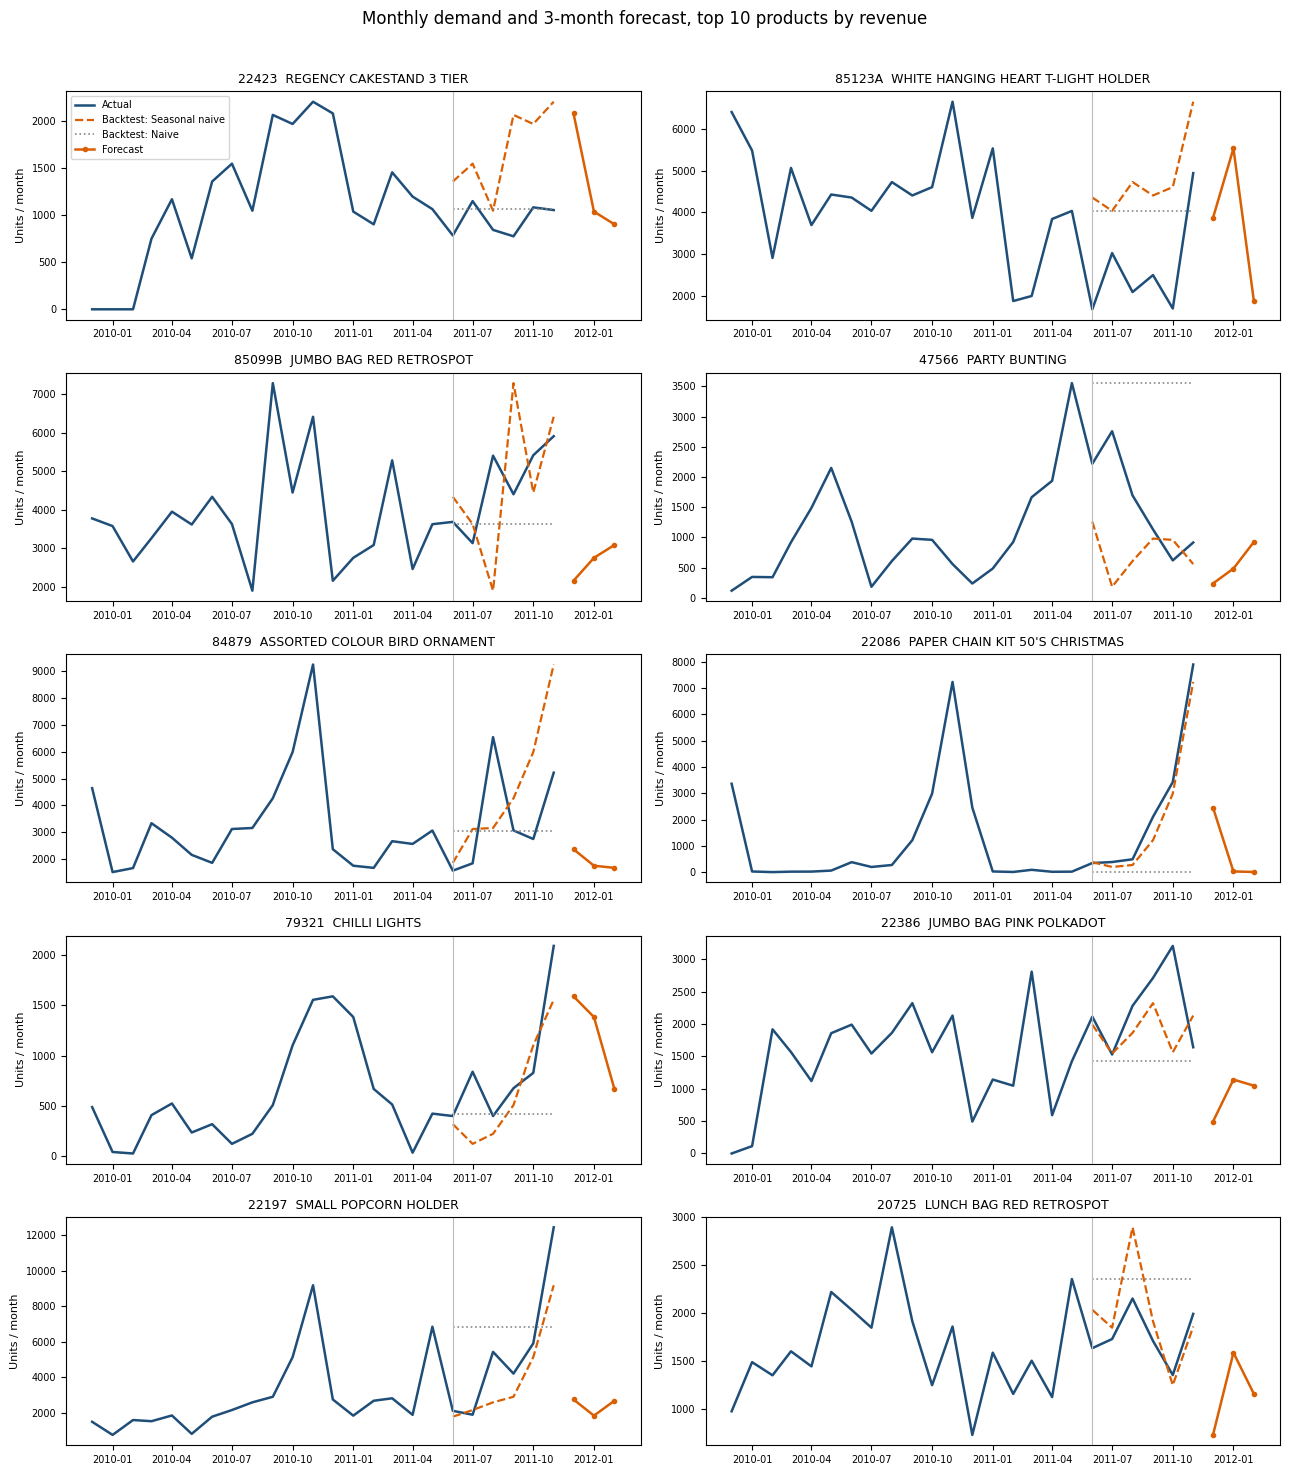

In [25]:
# ===== Project 2: Demand forecasting, top 10 products (paste as a NEW cell at the END of the notebook) =====
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.holtwinters import SimpleExpSmoothing, ExponentialSmoothing
warnings.filterwarnings("ignore")

# 1) Monthly units per product, same window as the SQL analysis (Dec 2009 - Nov 2011), C2 (carriage) excluded
lines = vbrp[["VBELN", "MATNR", "ARKTX", "FKIMG", "NETWR"]].merge(vbrk[["VBELN", "FKDAT"]], on="VBELN")
lines = lines[lines["MATNR"] != "C2"].copy()
lines["month"] = pd.to_datetime(lines["FKDAT"]).dt.to_period("M").dt.to_timestamp()
months = pd.date_range("2009-12-01", "2011-11-01", freq="MS")
lines = lines[lines["month"].isin(months)]

top = lines.groupby("MATNR")["NETWR"].sum().nlargest(10).index.tolist()
names = makt.set_index("MATNR")["MAKTX"]
units = (lines[lines["MATNR"].isin(top)]
         .groupby(["MATNR", "month"])["FKIMG"].sum()
         .unstack(0).reindex(months).fillna(0)[top])
print("Top 10 products by revenue:")
for c in top:
    print(f"  {c}  {names[c]}")

# 2) Five simple, explainable models
def f_naive(y, h):  return np.repeat(y[-1], h)                       # baseline: last month repeats
def f_snaive(y, h): return np.array([y[len(y) - 12 + i] for i in range(h)])  # same month last year
def f_ma3(y, h):    return np.repeat(y[-3:].mean(), h)               # 3-month moving average
def f_ses(y, h):    return SimpleExpSmoothing(y, initialization_method="estimated").fit().forecast(h)
def f_holt(y, h):   return ExponentialSmoothing(y, trend="add", damped_trend=True,
                                                initialization_method="estimated").fit().forecast(h)
models = {"Naive": f_naive, "Seasonal naive": f_snaive, "Moving avg (3m)": f_ma3,
          "Exp. smoothing": f_ses, "Holt damped trend": f_holt}

def wape(actual, pred):
    return np.abs(actual - pred).sum() / max(actual.sum(), 1e-9) * 100

# 3) Backtest: train on the first 18 months (Dec 2009 - May 2011), test on the last 6 (Jun - Nov 2011)
TRAIN, H = 18, 6
rows = []
bt_pred = {}
for c in top:
    y = units[c].values.astype(float)
    train, test = y[:TRAIN], y[TRAIN:]
    for mname, fn in models.items():
        pred = np.clip(np.asarray(fn(train, H), dtype=float), 0, None)
        bt_pred[(c, mname)] = pred
        rows.append({"StockCode": c, "Product": names[c], "Model": mname, "WAPE_%": round(wape(test, pred), 1)})
bt = pd.DataFrame(rows)
wide = bt.pivot(index="StockCode", columns="Model", values="WAPE_%").loc[top]
print("\nBacktest error (WAPE %, lower is better), last 6 months:")
print(wide.to_string())

summary = wide.median().sort_values()
print("\nMedian WAPE across the 10 products:")
print(summary.round(1).to_string())

# One model for all products (chosen on the median, to avoid picking a lucky model per product)
best = summary.index[0]
beats = int((wide[best] < wide["Naive"]).sum())
print(f"\nChosen model: {best}. It beats the naive baseline for {beats} of 10 products.")

# 4) Final forecast: refit on all 24 months, next 3 months
future = pd.date_range("2011-12-01", periods=3, freq="MS")
fc = pd.DataFrame({c: np.clip(np.asarray(models[best](units[c].values.astype(float), 3), dtype=float), 0, None)
                   for c in top}, index=future).round(0)
fc_long = fc.stack().reset_index()
fc_long.columns = ["Month", "StockCode", "ForecastUnits"]
fc_long["Product"] = fc_long["StockCode"].map(names)
fc_long["Model"] = best
print("\nForecast, next 3 months (units):")
print(fc.to_string())

# 5) Save for Excel / Power BI
bt.to_csv(OUTPUT_DIR + "forecast_backtest.csv", index=False)
fc_long.to_csv(OUTPUT_DIR + "forecast_next3.csv", index=False)
units.reset_index().rename(columns={"index": "Month"}).to_csv(OUTPUT_DIR + "monthly_units_top10.csv", index=False)

# 6) Chart
fig, axes = plt.subplots(5, 2, figsize=(13, 15), sharex=False)
for ax, c in zip(axes.ravel(), top):
    y = units[c]
    ax.plot(y.index, y.values, color="#1f4e79", lw=1.8, label="Actual")
    ax.plot(y.index[TRAIN:], bt_pred[(c, best)], color="#d95f02", lw=1.6, ls="--", label=f"Backtest: {best}")
    ax.plot(y.index[TRAIN:], bt_pred[(c, "Naive")], color="#888888", lw=1.2, ls=":", label="Backtest: Naive")
    ax.plot(fc.index, fc[c].values, color="#d95f02", lw=1.8, marker="o", ms=3, label="Forecast")
    ax.axvline(y.index[TRAIN], color="#bbbbbb", lw=0.8)
    ax.set_title(f"{c}  {str(names[c])[:34]}", fontsize=9)
    ax.tick_params(labelsize=7)
    ax.set_ylabel("Units / month", fontsize=8)
axes[0, 0].legend(fontsize=7, loc="upper left")
fig.suptitle("Monthly demand and 3-month forecast, top 10 products by revenue", fontsize=12)
fig.tight_layout(rect=[0, 0, 1, 0.97])
fig.savefig(IMG_DIR + "p2_01_forecast_top10.png", dpi=150)
plt.show()
